# 03 · Exploratory Data Analysis — customers & demand

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200); pd.set_option("display.float_format", "{:,.2f}".format)
from src.data_cleaning.loader import load_all_processed, load_all_raw
from src.kpi.kpis import kpi_by, compute_all_kpis
from src.analytics import eda
d = load_all_processed()
t, f, o, c = d["tickets_enriched"], d["customer_feedback"], d["operations"], d["customers"]
VIS = ROOT / "visualizations"
def show(*names):
    for n in names: display(Image(filename=str(VIS / f"{n}.png"), width=820))

In [2]:
k = compute_all_kpis(t, f, o, d["business_costs"])
pd.Series(k, name="value").to_frame()

,value
Total Tickets,"24,000.00"
Open Tickets,257.00
Closed Tickets,"23,236.00"
Pending Tickets,89.00
Escalated Tickets,"2,403.00"
Reopened Tickets,"1,932.00"
Avg First Response Time (h),5.76
Median First Response Time (h),1.14
Avg Resolution Time (h),34.46
First Contact Resolution Rate (%),21.49


## Customers

,customer_region,customers
0,North America,1261
1,Europe,975
2,Asia Pacific,633
3,Latin America,220
4,Middle East & Africa,111


,customer_segment,customers,median_clv,mean_clv,total_clv
0,Enterprise,394,"42,570.00","48,925.00","19,276,453.00"
1,Mid-Market,742,"12,298.00","14,268.00","10,586,738.00"
2,Small Business,951,"3,614.00","4,405.00","4,189,606.00"
3,Consumer,1113,637.00,794.00,"883,256.00"


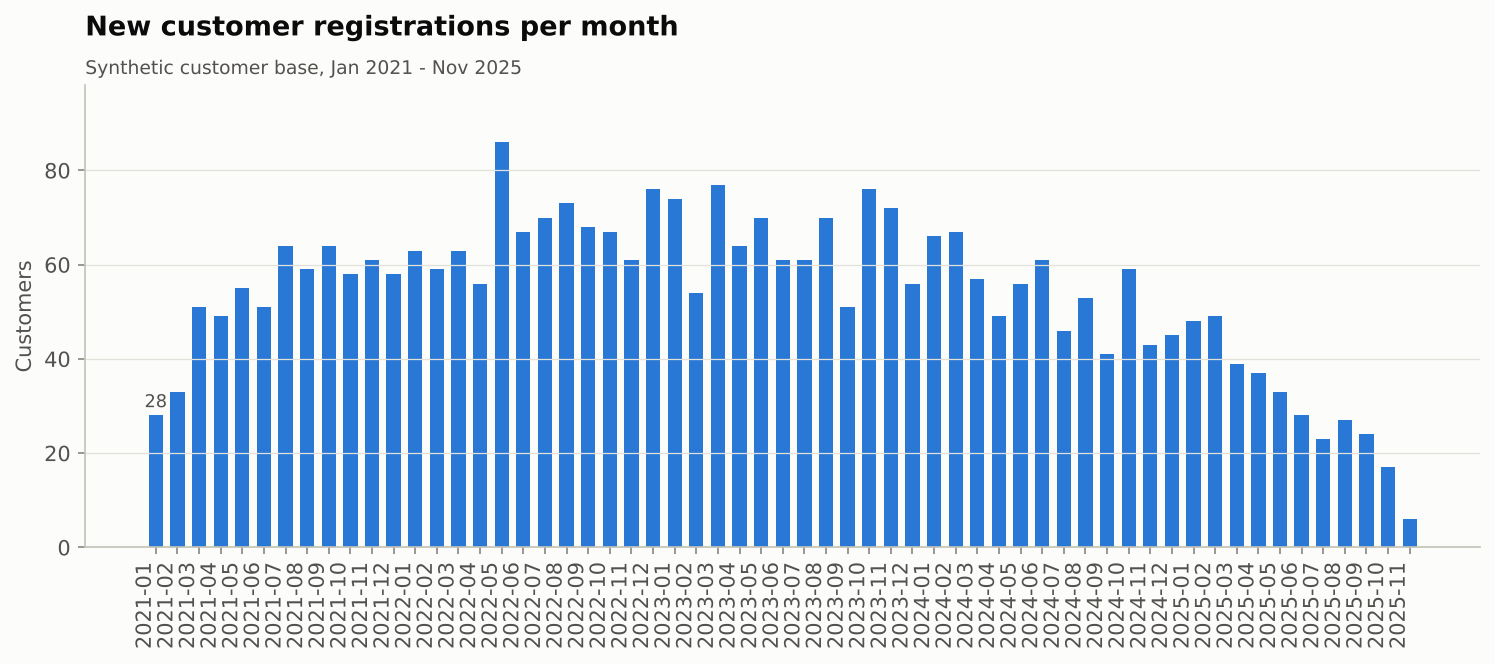

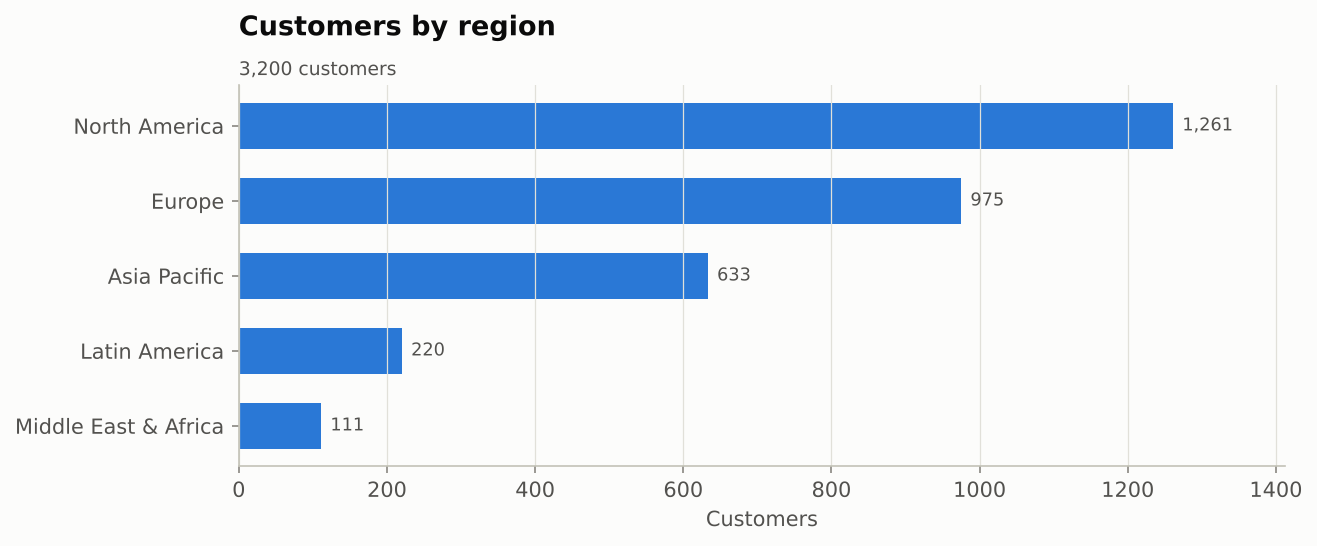

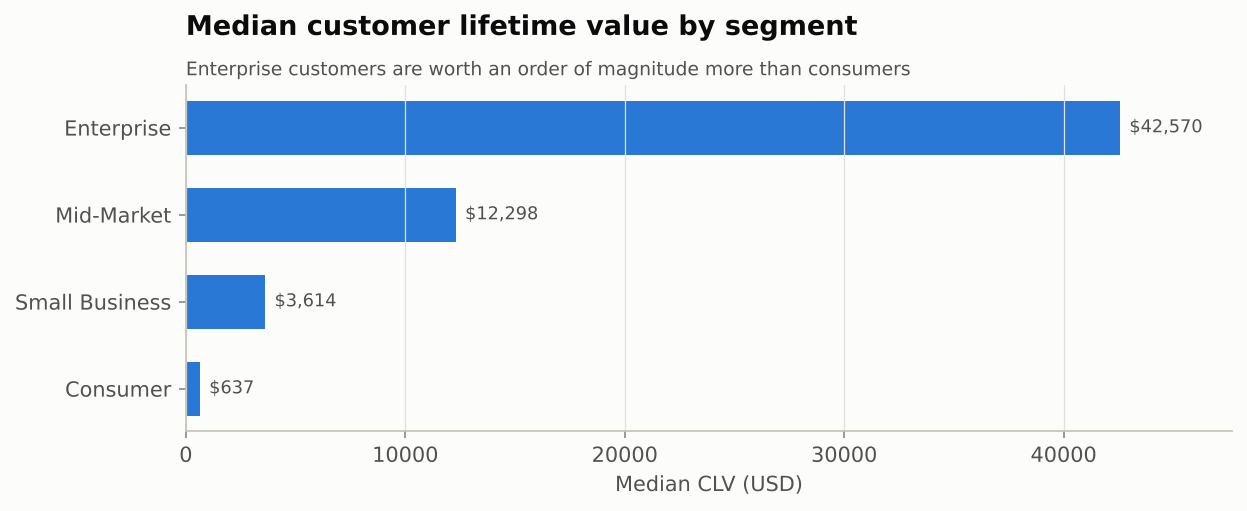

In [3]:
display(eda.customers_by(c, "customer_region")); display(eda.clv_by_segment(c))
show("01_new_customers_by_month", "02_customers_by_region", "03_clv_by_segment")

## Customer activity and repeat contacts

,tickets_per_customer,customers
0,0,607
1,1,439
2,2-3,582
3,4-5,360
4,6-10,533
5,11-20,392
6,21+,287


7-day repeat contact rate: 16.0%


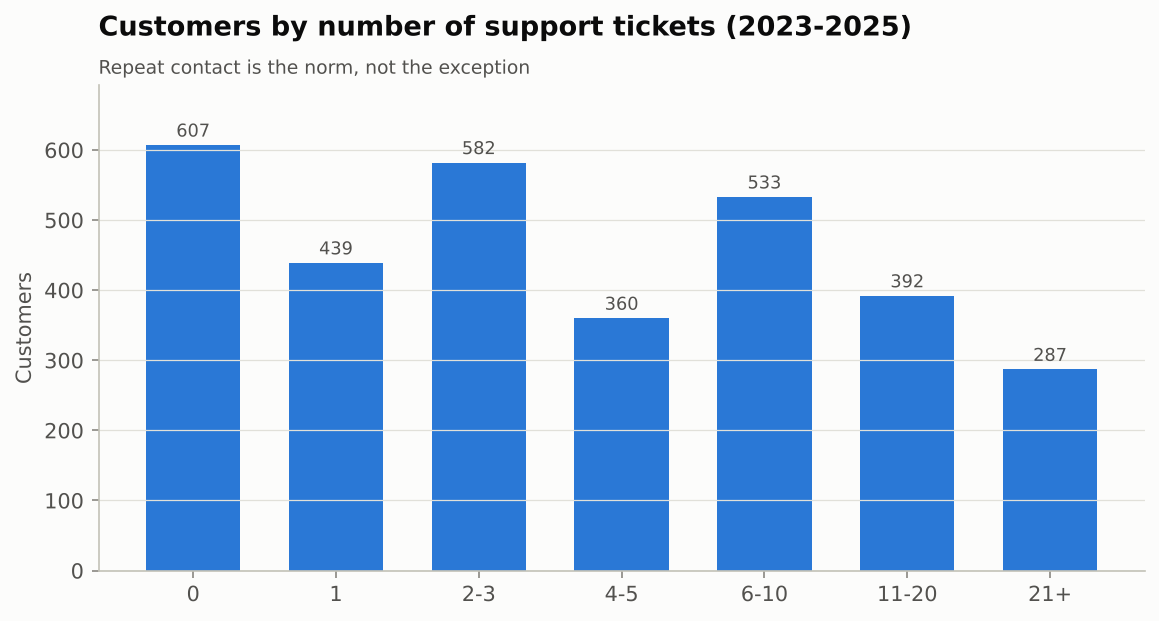

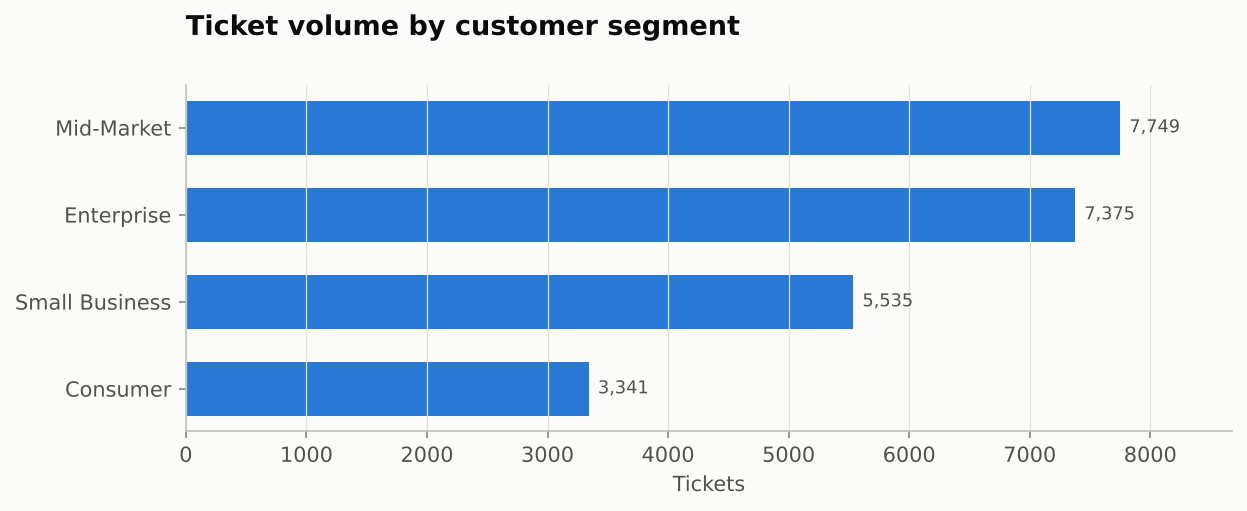

In [4]:
act = eda.customer_activity(t, c)
display(eda.tickets_per_customer_distribution(act))
print(f"7-day repeat contact rate: {t.is_repeat_contact.mean()*100:.1f}%")
show("04_tickets_per_customer", "05_tickets_by_segment")

## Ticket demand patterns

,ticket_category,tickets,share_pct
0,Technical Issue,5558,23.16
1,Billing & Payment,4885,20.35
2,Order Status,3084,12.85
3,Returns & Refunds,2832,11.80
4,Delivery Problem,2719,11.33
5,Account Access,2578,10.74
6,Product Inquiry,1368,5.70
7,Complaint,976,4.07


,support_channel,tickets,share_pct
0,Email,7885,32.85
1,Live Chat,5849,24.37
2,Phone,5283,22.01
3,Web Portal,3179,13.25
4,Social Media,1684,7.02
5,Unknown,120,0.50


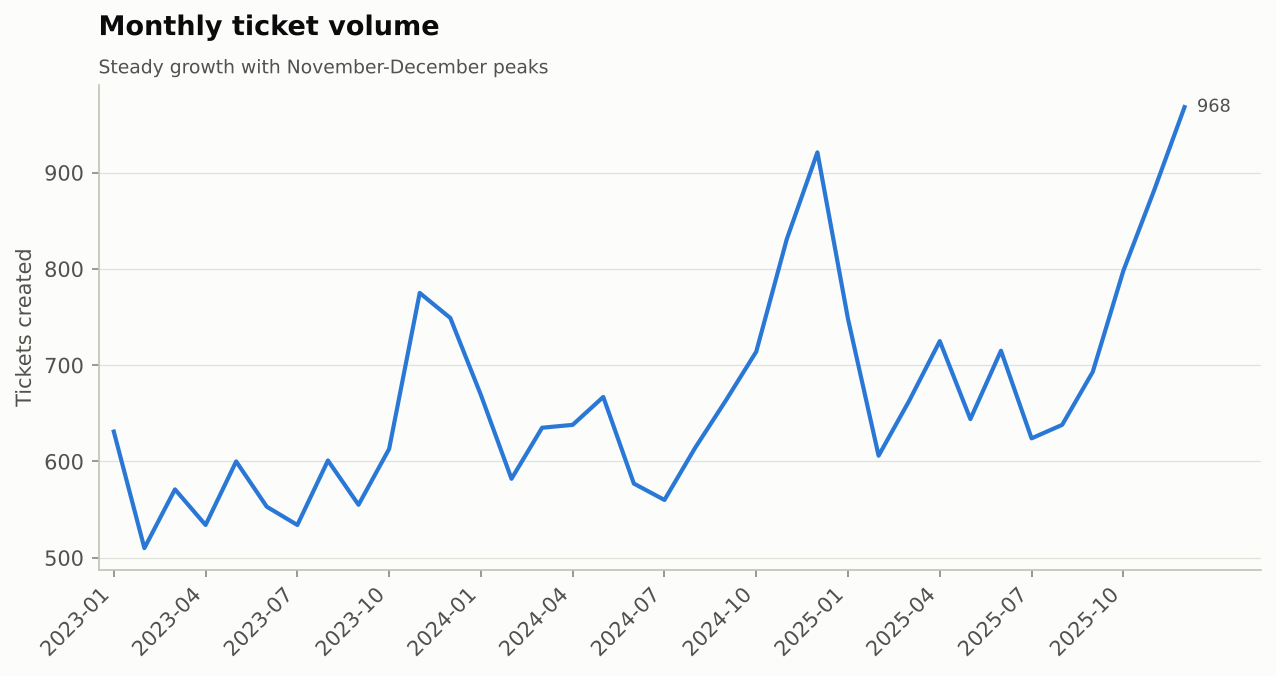

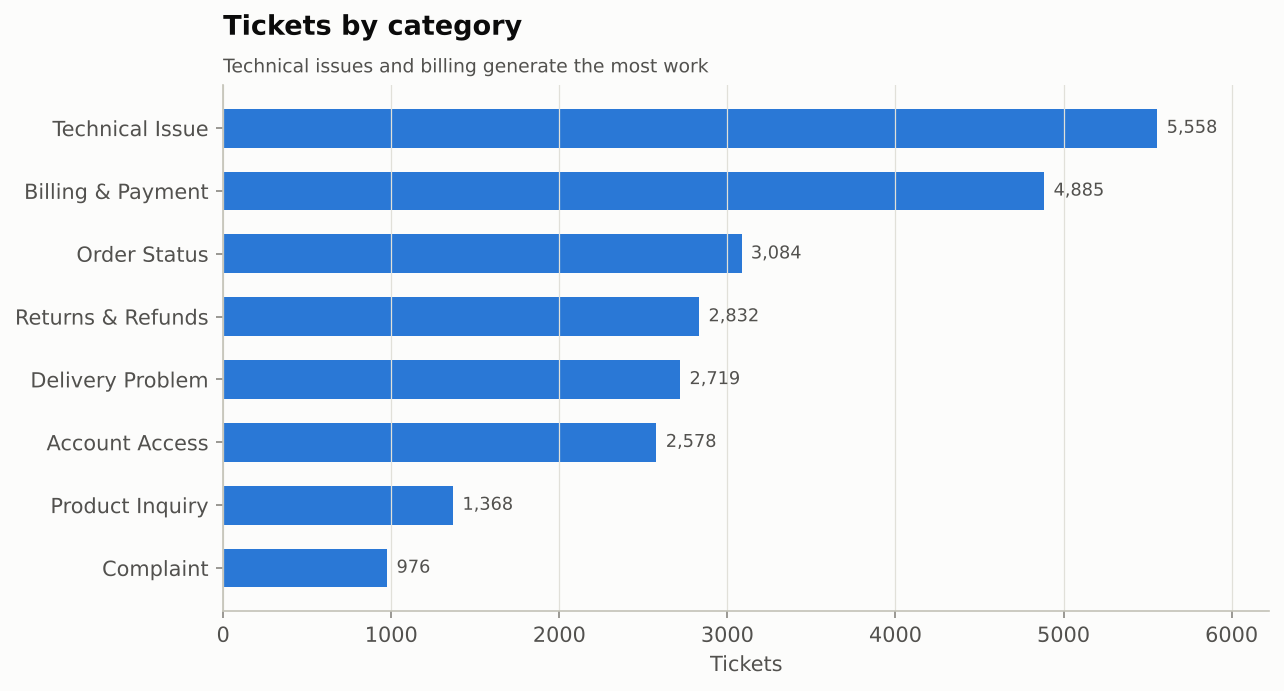

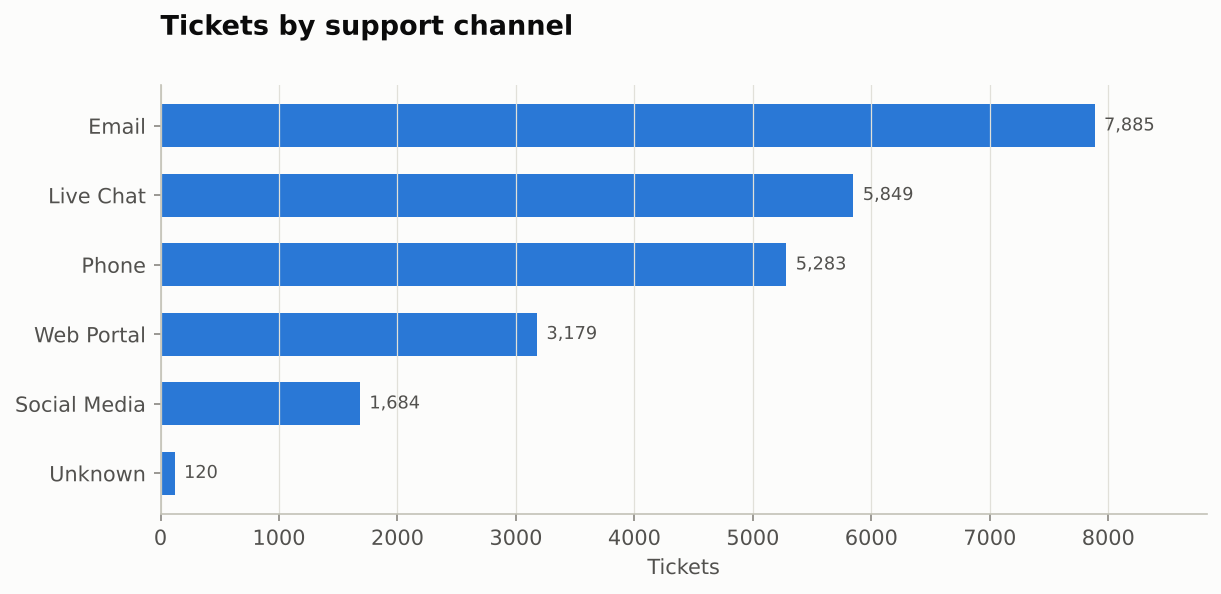

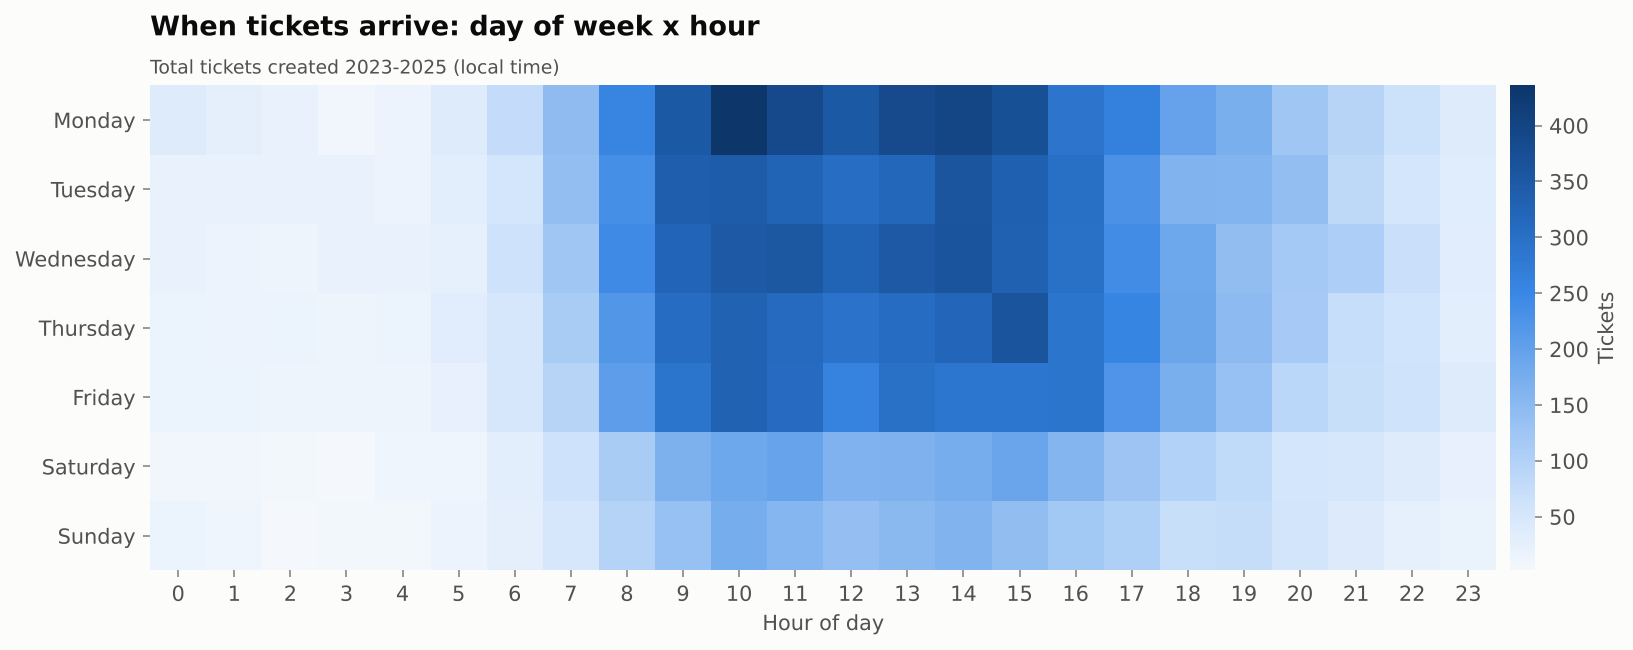

In [5]:
display(eda.volume_by(t, "ticket_category")); display(eda.volume_by(t, "support_channel"))
show("06_ticket_volume_trend", "07_tickets_by_category", "10_tickets_by_channel", "12_day_hour_heatmap")

## Observations (seed 42)
* Volume grows ~20% from 2023 to 2025 with clear **November-December peaks**.
* **Technical Issue** and **Billing & Payment** are the two largest categories; Billing's share jumps from April 2025.
* Demand is concentrated **Mon-Fri, 09:00-17:00**; weekends carry roughly half the weekday volume.
* Repeat contact is the norm: most contacting customers raise several tickets, and the top 10% of customers raise ~42% of tickets.
* Enterprise customers have a median CLV roughly 60x that of consumers.